# 07 — Layer-1 descriptives: does the deterministic rail measure anything?

**Purpose.** Face-validity exhibits for the Layer-1 relevance scores (02),
before any Layer-2 comparison exists: if the rail works, the firms and
industries a reader can predict should surface without being asked —
satellite firms on satellite topics, utilities on EPA regulation, telecoms
on broadband. Nothing here feeds the pipeline; these are Stage-1-style
raw-pattern figures (INV-26 spirit) for the measurement section.

**The score used everywhere below is a standardized score.** 02 measured
the raw top-5-mean cosine rising mechanically with filing length (decile
spread 1.74 sd), and raw cosines are not comparable across topics (some
centroids sit in denser semantic regions). Both confounds die in one move:
**z-score within (topic x filing-length decile)** — a filing's score is
expressed relative to all filings of similar length on the same topic.
Units: standard deviations; 0 = typical.

**Industry.** NAICS from `crsp_compustat_link.dta` (GVKEY join, first
3 digits); coverage printed. Figures label industries with official NAICS3
titles.

**Palette discipline.** The project palette (Navy data / Red reference /
Green comparison) is user-fixed. The dataviz validator flags navy/green as
low-chroma for *categorical* rotation — accepted deliberately: no figure
here rotates them as a categorical set; series are ≤2 per axes, direct-
labeled, and separated by line style, and CVD-separation/contrast checks
pass.

**Outputs.** `paper/figures/fig_relevance_top_pairs`,
`fig_relevance_industry_exposure`, `fig_relevance_industry_topics`,
`fig_relevance_industry_trends` (pdf + svg).

## Setup and style

The measured-layout helpers (`finish`, `wrap_to_px`) are the binding figure
system: legend one row below the x-title at the y-title's x, note wrapped
to the figure's exact pixel width, 0.3 cm gaps, no text inside the plot
area.

In [1]:
import sys

sys.path.insert(0, "../lib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from paths import DATA_REPO, FIGURES, relevance_run_dir

NAVY, RED, GREEN = "#003049", "#A30006", "#7C9885"
CHARCOAL, GRID = "#36454F", "#D0D0D0"
sns.set_theme(style="white", font="serif",
              rc={"font.serif": ["DejaVu Serif", "Times New Roman",
                                 "serif"], "font.size": 10,
                  "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                  "ytick.labelsize": 9.5})
CM_IN = 1 / 2.54


def wrap_to_px(fig, ren, text, width_px, fontsize=8):
    probe = fig.text(0, 0, "", fontsize=fontsize)
    out, curline = [], ""
    for word in text.split():
        trial = f"{curline} {word}".strip()
        probe.set_text(trial)
        if probe.get_window_extent(ren).width <= width_px or not curline:
            curline = trial
        else:
            out.append(curline); curline = word
    out.append(curline); probe.remove()
    return "\n".join(out)


def finish(fig, anchor_ax, stem, note, ncol=0, right_x1px=None):
    fig.canvas.draw()
    ren = fig.canvas.get_renderer()
    W, H = fig.bbox.width, fig.bbox.height
    gap = 0.3 * CM_IN * fig.dpi
    x0px = anchor_ax.yaxis.label.get_window_extent(ren).x0
    x1px = right_x1px if right_x1px is not None else \
        max(a.get_window_extent(ren).x1 for a in fig.axes)
    bot = min(a.xaxis.label.get_window_extent(ren).y0 for a in fig.axes
              if a.get_xlabel())
    if ncol:
        handles, labels = anchor_ax.get_legend_handles_labels()
        leg_ = fig.legend(handles, labels, frameon=False, loc="upper left",
                          bbox_to_anchor=(x0px / W, (bot - gap) / H),
                          bbox_transform=fig.transFigure, ncol=ncol,
                          fontsize=9, handlelength=1.8, columnspacing=1.4)
        fig.canvas.draw()
        note_top = leg_.get_window_extent(ren).y0 - gap
    else:
        note_top = bot - gap
    fig.text(x0px / W, note_top / H,
             wrap_to_px(fig, ren, note, x1px - x0px), ha="left", va="top",
             fontsize=8, color="0.35", linespacing=1.4)
    for ext in ("pdf", "svg"):
        fig.savefig(FIGURES / f"{stem}.{ext}", bbox_inches="tight")
    print(f"saved {stem}.pdf/.svg")


def shorten(s, n=42):
    return s if len(s) <= n else s[:n - 1].rstrip() + "…" 

## Data — standardized scores with industry codes

One frame, built once: every (filing, topic) score, its within-
(topic x length-decile) z, the firm name, and NAICS3. Coverage of the
NAICS join is printed, not assumed.

In [2]:
SCORES = relevance_run_dir("scores")

scores = pd.read_parquet(SCORES / "firm_topic_scores.parquet")
scores["score"] = scores["score"].astype("float64")   # float32 breaks the
                                                      # exact-z assert below
topics = pd.read_parquet(SCORES / "topic_index.parquet",
                         columns=["topic_id", "theme_id", "label"])
scores = scores.merge(topics, on="topic_id")

# one decile per filing (n_sentences is constant within accessionNo)
fil = scores.drop_duplicates("accessionNo")[["accessionNo", "n_sentences"]]
fil["len_decile"] = pd.qcut(fil["n_sentences"], 10, labels=False,
                            duplicates="drop")
scores = scores.merge(fil[["accessionNo", "len_decile"]], on="accessionNo")

g = scores.groupby(["topic_id", "len_decile"])["score"]
scores["z"] = (scores["score"] - g.transform("mean")) / g.transform("std")

meta = pd.read_parquet(
    DATA_REPO / "raw" / "03_sp500_10k_item1" / "sp500_10k_item1.parquet",
    columns=["accessionNo", "conm"]).drop_duplicates("accessionNo")
scores = scores.merge(meta, on="accessionNo")

link = pd.read_stata(DATA_REPO / "raw" / "01_firm_id" /
                     "crsp_compustat_link.dta",
                     columns=["GVKEY", "naics"])
link["naics"] = link["naics"].astype(str).str.strip()
link = link.loc[link["naics"].str.len() >= 3]
link["naics3"] = link["naics"].str[:3]
naics_map = (link.groupby("GVKEY")["naics3"]
             .agg(lambda s: s.mode().iloc[0]))
scores["naics3"] = scores["gvkey"].map(naics_map)

n_f = scores["gvkey"].nunique()
n_c = scores.loc[scores["naics3"].notna(), "gvkey"].nunique()
print(f"filings x topics : {len(scores):,}")
print(f"NAICS3 coverage  : {n_c:,} of {n_f:,} firms ({n_c / n_f:.1%})")
print(f"industries       : {scores['naics3'].nunique()}")

NAICS3 = {
    "211": "Oil & Gas Extraction", "212": "Mining (ex. Oil & Gas)",
    "213": "Mining Support Activities", "221": "Utilities",
    "236": "Building Construction", "237": "Heavy & Civil Construction",
    "311": "Food Manufacturing", "312": "Beverage & Tobacco",
    "313": "Textile Mills", "315": "Apparel Manufacturing",
    "316": "Leather Products", "321": "Wood Products",
    "322": "Paper Manufacturing", "323": "Printing",
    "324": "Petroleum & Coal Products", "325": "Chemicals (incl. Pharma)",
    "326": "Plastics & Rubber", "327": "Nonmetallic Minerals",
    "331": "Primary Metals", "332": "Fabricated Metals",
    "333": "Machinery Manufacturing", "334": "Computer & Electronic Products",
    "335": "Electrical Equipment", "336": "Transportation Equipment",
    "337": "Furniture", "339": "Misc. Manufacturing",
    "423": "Wholesale: Durable Goods", "424": "Wholesale: Nondurable Goods",
    "425": "Wholesale Electronic Markets", "441": "Motor Vehicle Dealers",
    "444": "Building Material Retail", "445": "Food & Beverage Retail",
    "446": "Health & Personal Care Retail", "448": "Clothing Retail",
    "452": "General Merchandise Retail", "454": "Nonstore Retail",
    "455": "General Merchandise Retail", "456": "Health Retail",
    "458": "Clothing Retail", "459": "Sporting/Hobby/Misc. Retail",
    "481": "Air Transportation", "482": "Rail Transportation",
    "483": "Water Transportation", "484": "Truck Transportation",
    "486": "Pipeline Transportation", "488": "Transportation Support",
    "492": "Couriers & Messengers", "493": "Warehousing & Storage",
    "511": "Publishing (incl. Software)", "512": "Motion Picture & Sound",
    "513": "Publishing & Broadcasting", "515": "Broadcasting",
    "516": "Broadcasting & Content", "517": "Telecommunications",
    "518": "Data Processing & Hosting", "519": "Other Information Services",
    "521": "Monetary Authorities", "522": "Credit Intermediation (Banks)",
    "523": "Securities & Investments", "524": "Insurance",
    "525": "Funds & Trusts", "531": "Real Estate",
    "532": "Rental & Leasing", "533": "Intangible Asset Lessors",
    "541": "Professional & Technical Services",
    "551": "Management of Companies", "561": "Administrative Support",
    "562": "Waste Management", "611": "Educational Services",
    "621": "Ambulatory Health Care", "622": "Hospitals",
    "623": "Nursing Care", "624": "Social Assistance",
    "713": "Amusement & Recreation", "721": "Accommodation",
    "722": "Food Services & Bars", "811": "Repair & Maintenance",
}


def ind_name(code):
    return NAICS3.get(code, f"NAICS {code}")

filings x topics : 2,438,226
NAICS3 coverage  : 1,060 of 1,061 firms (99.9%)
industries       : 84


## Figure 1 — The strongest firm-topic matches

Top 15 (firm, topic) pairs by the firm's mean z across its filings
(firms with >= 3 filings, so one odd document cannot own a row). The
exhibit works only if a reader nods at every row without explanation —
that is the test.

saved fig_relevance_top_pairs.pdf/.svg


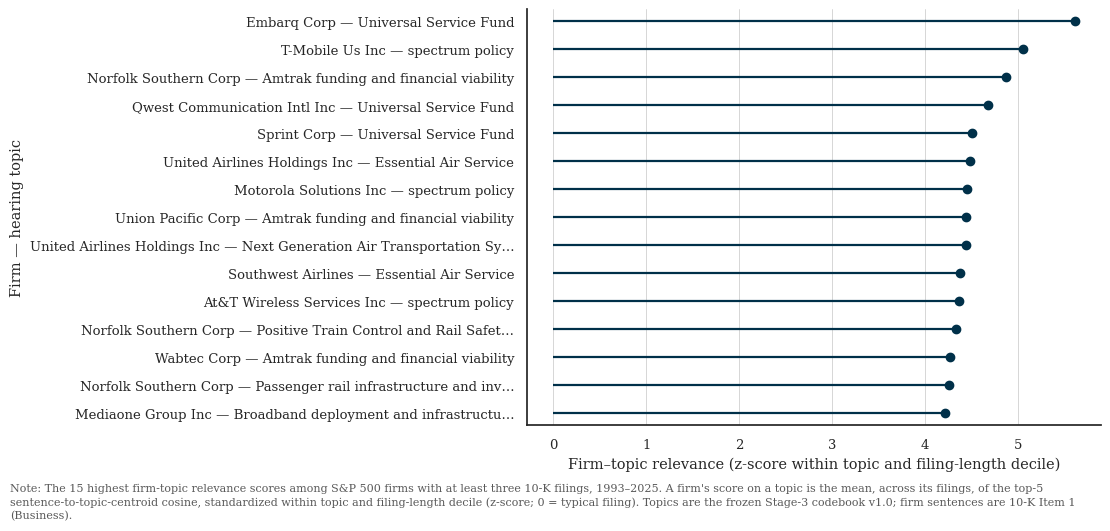

In [3]:
firm_topic = (scores.groupby(["gvkey", "conm", "topic_id", "label"])
              .agg(z=("z", "mean"), n=("z", "size")).reset_index())
firm_topic = firm_topic.loc[firm_topic["n"] >= 3]
top = firm_topic.nlargest(15, "z").iloc[::-1]

labels = [f"{r.conm.title()} — {shorten(r.label, 38)}"
          for r in top.itertuples()]

fig, ax = plt.subplots(figsize=(7.4, 5.4))
ax.hlines(range(len(top)), 0, top["z"], color=NAVY, lw=1.6)
ax.plot(top["z"], range(len(top)), "o", color=NAVY, ms=6)
ax.set_yticks(range(len(top)), labels)
ax.set_xlabel("Firm–topic relevance "
              "(z-score within topic and filing-length decile)")
ax.set_ylabel("Firm — hearing topic")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.margins(y=0.03)

finish(fig, ax, "fig_relevance_top_pairs",
       "Note: The 15 highest firm-topic relevance scores among S&P 500 "
       "firms with at least three 10-K filings, 1993–2025. A firm's "
       "score on a topic is the mean, across its filings, of the top-5 "
       "sentence-to-topic-centroid cosine, standardized within topic and "
       "filing-length decile (z-score; 0 = typical filing). Topics are the "
       "frozen Stage-3 codebook v1.0; firm sentences are 10-K Item 1 "
       "(Business).")
plt.show()

## Figure 2 — Which industries live on the science-committee agenda

The reference-figure analog: mean z across all 111 topics per industry —
overall exposure of the industry's business language to this hearing
agenda — with a 95% CI over firms (firm means first, so a firm with thirty
filings is still one observation). Eight most- and eight least-exposed
industries with >= 8 firms.

saved fig_relevance_industry_exposure.pdf/.svg


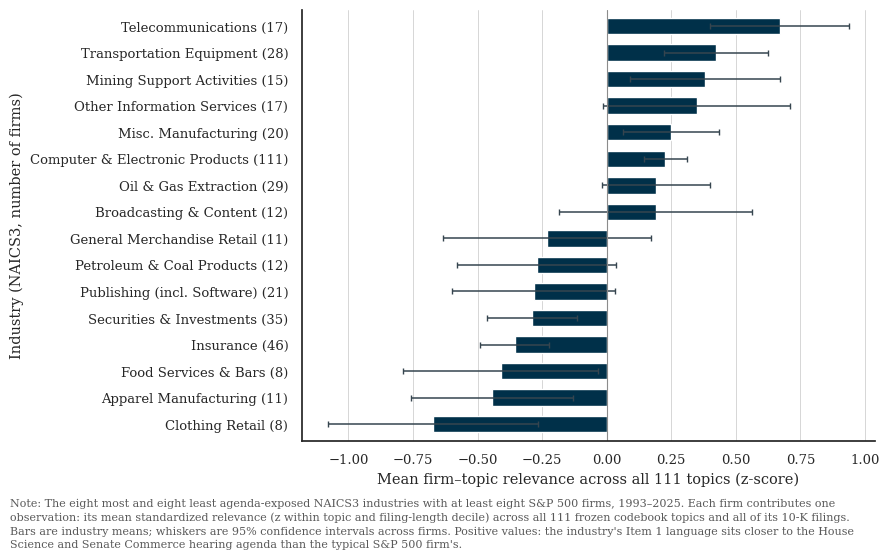

In [4]:
firm_ind = (scores.dropna(subset=["naics3"])
            .groupby(["gvkey", "naics3"])["z"].mean().reset_index())
ind = (firm_ind.groupby("naics3")["z"]
       .agg(mean="mean", sd="std", n="size").reset_index())
ind = ind.loc[ind["n"] >= 8]
ind["ci"] = 1.96 * ind["sd"] / np.sqrt(ind["n"])
ind = ind.sort_values("mean")
show = pd.concat([ind.head(8), ind.tail(8)])

names = [f"{ind_name(r.naics3)} ({int(r.n)})" for r in show.itertuples()]

fig, ax = plt.subplots(figsize=(7.4, 5.6))
ax.barh(range(len(show)), show["mean"], color=NAVY, height=0.62)
ax.errorbar(show["mean"], range(len(show)), xerr=show["ci"], fmt="none",
            ecolor=CHARCOAL, elinewidth=1.1, capsize=2.5)
ax.axvline(0, color="0.55", lw=0.8)
ax.set_yticks(range(len(show)), names)
ax.set_xlabel("Mean firm–topic relevance across all 111 topics "
              "(z-score)")
ax.set_ylabel("Industry (NAICS3, number of firms)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.margins(y=0.02)

finish(fig, ax, "fig_relevance_industry_exposure",
       "Note: The eight most and eight least agenda-exposed NAICS3 "
       "industries with at least eight S&P 500 firms, 1993–2025. Each "
       "firm contributes one observation: its mean standardized relevance "
       "(z within topic and filing-length decile) across all 111 frozen "
       "codebook topics and all of its 10-K filings. Bars are industry "
       "means; whiskers are 95% confidence intervals across firms. "
       "Positive values: the industry's Item 1 language sits closer to the "
       "House Science and Senate Commerce hearing agenda than the typical "
       "S&P 500 firm's.")
plt.show()

## Figure 3 — Each industry's own agenda

For eight industries with strong priors: the three topics that industry
scores highest on. Dot plot, one block per industry. Read: does the
telecom block say broadband, the utility block say EPA, the aerospace
block say space?

saved fig_relevance_industry_topics.pdf/.svg


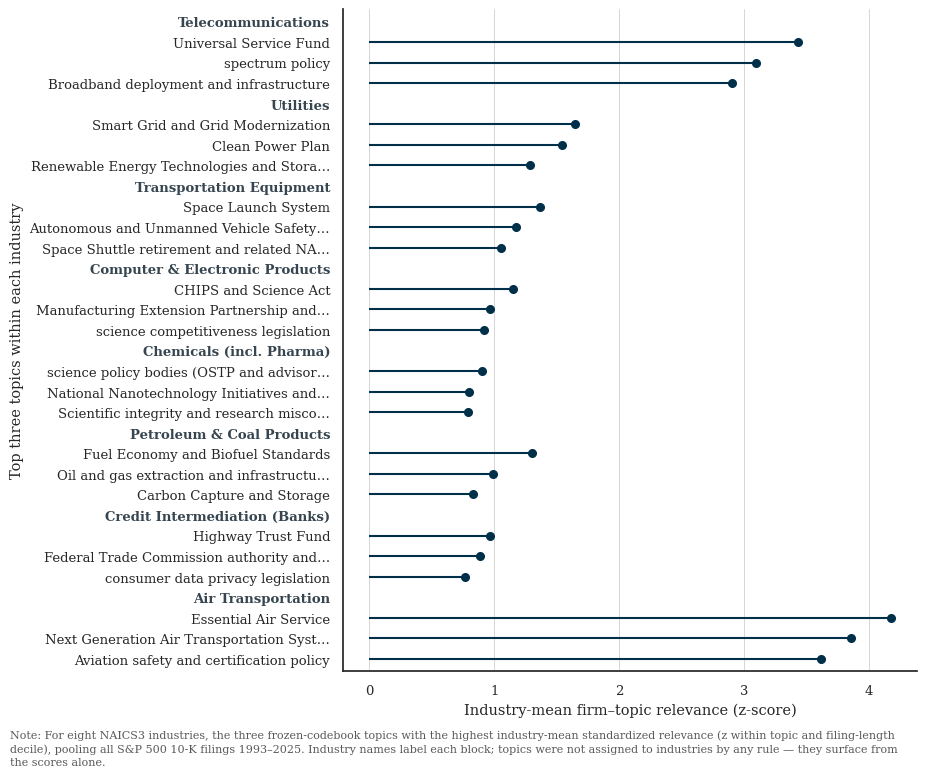

In [5]:
PICK = ["517", "221", "336", "334", "325", "324", "522", "481"]
ind_topic = (scores.dropna(subset=["naics3"])
             .groupby(["naics3", "topic_id", "label"])["z"]
             .mean().reset_index())

# industry headers occupy their own y-rows (bold, no mark) — an overlaid
# header text collides with the topic tick labels
entries = []
for code in PICK:
    entries.append((ind_name(code), None))
    top3 = ind_topic.loc[ind_topic["naics3"] == code].nlargest(3, "z")
    for r in top3.itertuples():
        entries.append((shorten(r.label, 40), r.z))

fig, ax = plt.subplots(figsize=(7.4, 8.6))
y = np.arange(len(entries))[::-1]
for yi, (_, v) in zip(y, entries):
    if v is not None:
        ax.hlines(yi, 0, v, color=NAVY, lw=1.5)
        ax.plot([v], [yi], "o", color=NAVY, ms=5.5)
ax.set_yticks(y, [lab for lab, _ in entries])
for tick, (lab, v) in zip(ax.get_yticklabels(), entries):
    if v is None:
        tick.set_fontweight("bold")
        tick.set_color(CHARCOAL)
# header rows carry no mark, so the data limits exclude the top row —
# set limits over the tick range explicitly or the first header clips
ax.set_ylim(-0.6, len(entries) - 0.4)
ax.set_xlabel("Industry-mean firm–topic relevance (z-score)")
ax.set_ylabel("Top three topics within each industry")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, lw=0.6)
ax.set_axisbelow(True)


finish(fig, ax, "fig_relevance_industry_topics",
       "Note: For eight NAICS3 industries, the three frozen-codebook "
       "topics with the highest industry-mean standardized relevance "
       "(z within topic and filing-length decile), pooling all S&P 500 "
       "10-K filings 1993–2025. Industry names label each block; "
       "topics were not assigned to industries by any rule — they "
       "surface from the scores alone.")
plt.show()

## Figure 4 — Six industry-topic pairs over time

For six industries, the top topic from Figure 3 traced yearly: industry-
mean z (navy) against the all-industry mean for the same topic (green
dashed, ≈ 0 by construction). Small multiples, one pair per panel
(INV-12 panel labels). The check: does the line sit where the industry's
history says it should?

saved fig_relevance_industry_trends.pdf/.svg


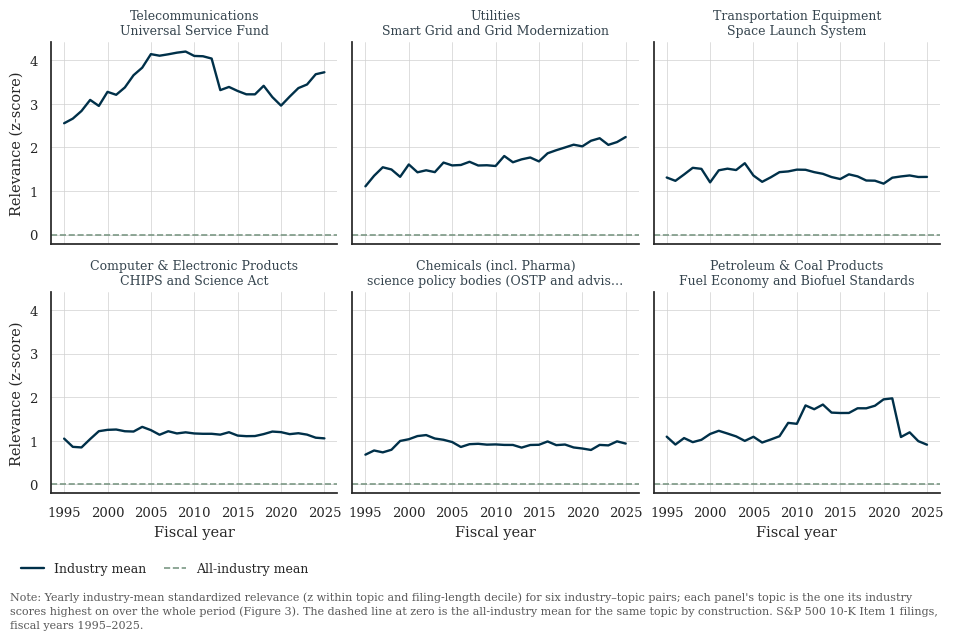

In [6]:
PAIRS = []
for code in ["517", "221", "336", "334", "325", "324"]:
    best = ind_topic.loc[ind_topic["naics3"] == code].nlargest(1, "z")
    PAIRS.append((code, int(best["topic_id"].iloc[0]),
                  best["label"].iloc[0]))

yearly = (scores.dropna(subset=["naics3"])
          .groupby(["naics3", "topic_id", "fyear"])["z"].mean())

fig, axes = plt.subplots(2, 3, figsize=(9.6, 5.6), sharex=True, sharey=True)
for ax, (code, tid, lab) in zip(axes.flat, PAIRS):
    s = yearly.loc[code, tid]
    s = s.loc[(s.index >= 1995) & (s.index <= 2025)]
    ax.plot(s.index, s.values, color=NAVY, lw=1.7,
            label="Industry mean")
    ax.axhline(0, color=GREEN, lw=1.2, ls="--",
               label="All-industry mean")
    ax.set_title(f"{ind_name(code)}\n{shorten(lab, 38)}", fontsize=9,
                 color=CHARCOAL)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=GRID, lw=0.5)
    ax.set_axisbelow(True)
for ax in axes[1]:
    ax.set_xlabel("Fiscal year")
for ax in axes[:, 0]:
    ax.set_ylabel("Relevance (z-score)")
fig.tight_layout()

finish(fig, axes[1, 0], "fig_relevance_industry_trends",
       "Note: Yearly industry-mean standardized relevance (z within topic "
       "and filing-length decile) for six industry–topic pairs; each "
       "panel's topic is the one its industry scores highest on over the "
       "whole period (Figure 3). The dashed line at zero is the "
       "all-industry mean for the same topic by construction. S&P 500 "
       "10-K Item 1 filings, fiscal years 1995–2025.",
       ncol=2)
plt.show()

## Verification

The four files exist and are fresh; the standardization holds (z mean
≈ 0, sd ≈ 1 within cells); the exhibits' claims are recomputed
as numbers so the reader of this notebook sees them without the PDFs.

In [7]:
import os
import time

for stem in ("fig_relevance_top_pairs", "fig_relevance_industry_exposure",
             "fig_relevance_industry_topics",
             "fig_relevance_industry_trends"):
    p = FIGURES / f"{stem}.pdf"
    assert p.exists() and time.time() - p.stat().st_mtime < 3600, stem
    print(f"1) {stem}.pdf  ({p.stat().st_size / 1e3:.0f} KB)")

chk = scores.groupby(["topic_id", "len_decile"])["z"].agg(["mean", "std"])
assert abs(chk["mean"]).max() < 1e-6 and abs(chk["std"] - 1).max() < 1e-6
print("2) z is exactly standardized within (topic, length decile)")

print("\n3) top five firm-topic pairs (the face-validity read):")
for r in firm_topic.nlargest(5, "z").itertuples():
    print(f"   z={r.z:4.1f}  {r.conm.title()}  —  {r.label}")

1) fig_relevance_top_pairs.pdf  (25 KB)
1) fig_relevance_industry_exposure.pdf  (26 KB)
1) fig_relevance_industry_topics.pdf  (39 KB)
1) fig_relevance_industry_trends.pdf  (26 KB)
2) z is exactly standardized within (topic, length decile)

3) top five firm-topic pairs (the face-validity read):
   z= 5.6  Embarq Corp  —  Universal Service Fund
   z= 5.1  T-Mobile Us Inc  —  spectrum policy
   z= 4.9  Norfolk Southern Corp  —  Amtrak funding and financial viability
   z= 4.7  Qwest Communication Intl Inc  —  Universal Service Fund
   z= 4.5  Sprint Corp  —  Universal Service Fund
